In [6]:
import matplotlib.pyplot as plt


def graph_function(function, start=-5, end=5, samples=401):
    x_values = [start + (end - start) * index / (samples - 1)
                for index in range(samples)]
    y_values = [function(x_value) for x_value in x_values]
    figure, axes = plt.subplots()
    axes.plot(x_values, y_values, label="y")
    axes.set(xlabel="x", ylabel="y")
    axes.axhline(0, color="gray", linewidth=0.5)
    axes.axvline(0, color="gray", linewidth=0.5)
    axes.grid(True)
    axes.legend()
    plt.show()
    return axes


def graph_until_intersection(function, start=0, end=10, samples=1001):
    x_values = [start]
    first_y, second_y = function(start)
    first_values = [first_y]
    second_values = [second_y]
    previous_difference = first_y - second_y
    intersection = None

    for index in range(1, samples):
        x_value = start + (end - start) * index / (samples - 1)
        first_y, second_y = function(x_value)
        difference = first_y - second_y
        if difference == 0 and previous_difference != 0:
            intersection = x_value
        elif difference * previous_difference < 0:
            lower = x_values[-1]
            upper = x_value
            lower_difference = previous_difference
            for iteration in range(40):
                midpoint = (lower + upper) / 2
                midpoint_first, midpoint_second = function(midpoint)
                midpoint_difference = midpoint_first - midpoint_second
                if midpoint_difference == 0:
                    lower = upper = midpoint
                    break
                if midpoint_difference * lower_difference > 0:
                    lower = midpoint
                    lower_difference = midpoint_difference
                else:
                    upper = midpoint
            intersection = (lower + upper) / 2

        if intersection is not None:
            x_value = intersection
            first_y, second_y = function(x_value)
        x_values.append(x_value)
        first_values.append(first_y)
        second_values.append(second_y)
        previous_difference = difference
        if intersection is not None:
            break

    figure, axes = plt.subplots()
    axes.plot(x_values, first_values, label="y1")
    axes.plot(x_values, second_values, label="y2")
    axes.set(xlabel="x", ylabel="y")
    axes.grid(True)
    axes.legend()
    if intersection is not None:
        axes.scatter([intersection], [first_values[-1]], color="black", zorder=3)
        print(f"Intersection: x = {intersection:.6g}, y = {first_values[-1]:.6g}")
    else:
        print(f"No crossing or sampled intersection found after x = {start} through x = {end}.")
    plt.show()
    return axes

# 2.1 Challenge: Graphing Numbers and Arithmetic

Run the helper code block at the very top once before running these challenges. It loads Matplotlib and the graphing helpers. If Matplotlib is not installed, run `%pip install matplotlib` in a new code cell, then rerun the helper block.

A function takes an input and returns an output. Here, `x1` is the input and `return` supplies the height of the graph. Change the arithmetic inside each function, then rerun its code block. The helpers handle drawing the graph.

## Example

A constant is a number that does not change with `x1`, so its graph is a horizontal line.

1. Predict where the horizontal line will appear, then run the block.
2. Change `number` to a negative integer, then to a decimal.
3. Set `number` to an arithmetic expression such as `9 / 2`. Predict the height before running it.

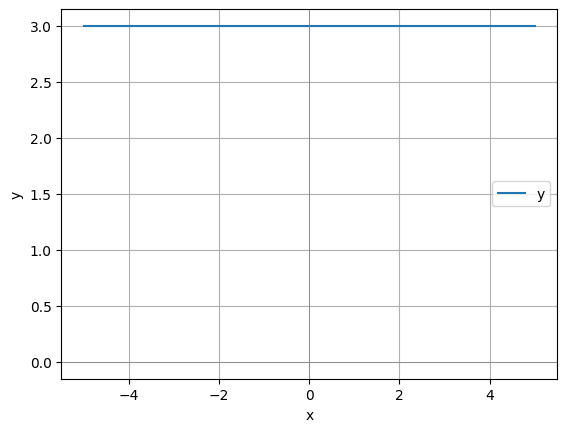

In [7]:
# Example
number = 3


def constant(x1):
    return number


graph_function(constant);

## Single Function

1. Predict the outputs at `x1 = -2`, `0`, and `2`, then graph the starting function.
2. Make a straight line using multiplication and addition.
3. Make a curve using `x1 ** 2`.
4. Move that curve up by `3`, then flip it below the x-axis using a negative multiplier.
5. Try `x1 ** 3` and `x1 / 2`. Explain how their graphs differ.

Only change the expression assigned to `y1`. The default graph shows inputs from `-5` to `5`.

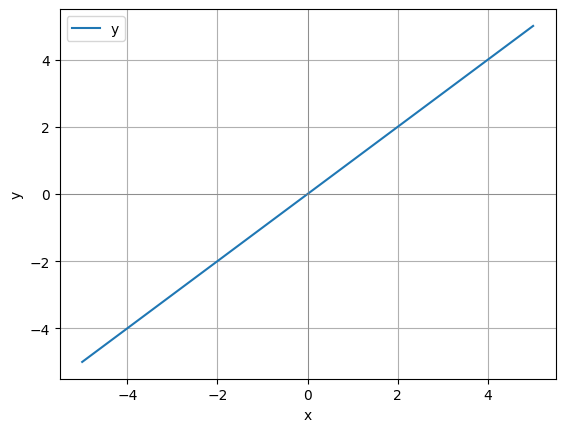

In [8]:
# Single Function
def single_function(x1):
    y1 = x1
    return y1


graph_function(single_function);

## Graph until intersection of 2 functions

The function below returns two outputs, `(y1, y2)`, for each input. The helper draws both graphs from `x = 0` and stops at their next intersection. A shared starting point is intentionally skipped.

1. Predict the next intersection of `x1 ** 2` and `2 * x1` after `x = 0`, then run the block.
2. Change `2 * x1` to `3 * x1`. Predict both coordinates of the next intersection.
3. Try `0.5 * x1`. What changes when the multiplier is a decimal?
4. Try `y1 = x1 + 1` and `y2 = 2 * x1`. Predict where they meet.
5. Create two functions that never intersect. What does the helper report?

The default search ends at `x = 10`. To search farther, change the call to `graph_until_intersection(two_functions, end=20)`.

Use functions that are continuous over the search range (no jumps or division by zero). The helper detects crossings and intersections exactly on a sample; a touching point between samples may be missed.

Intersection: x = 2, y = 4


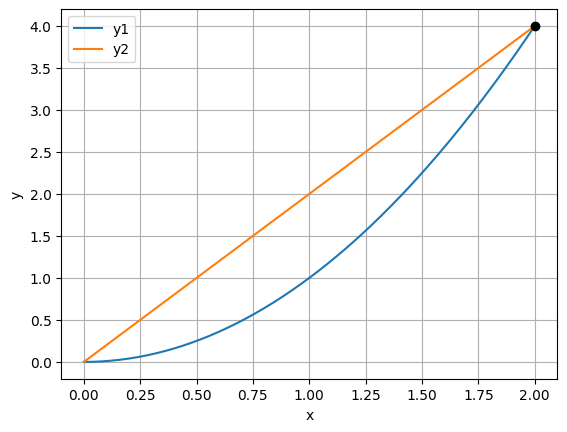

In [9]:
# Graph until intersection of 2 functions
def two_functions(x1):
    y1 = x1 ** 2
    y2 = 2 * x1
    return (y1, y2)


graph_until_intersection(two_functions);